# Analyse d'image

### Importation des modules

In [22]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

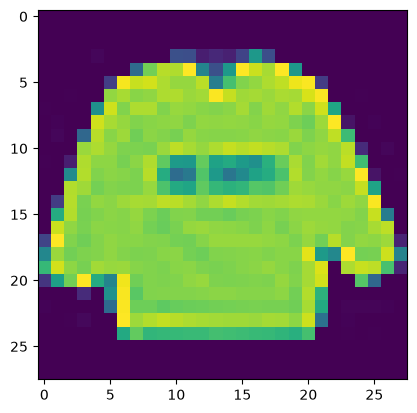

In [23]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

### Préparation des données d'apprentissage

In [24]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:, 0]))

X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [25]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_validation = X_validation.astype('float32')
X_validation /= 255

### Préparation des données de tests

In [26]:
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_test = X_test.astype('float32')
X_test /= 255

### Configuration

In [27]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

reseauNeurone1Convolution = Sequential()

reseauNeurone1Convolution.add(Input(shape=dimentionImage))

reseauNeurone1Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))

reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

reseauNeurone1Convolution.add(Dropout(0.2))

reseauNeurone1Convolution.add(Flatten())

reseauNeurone1Convolution.add(Dense(128, activation='relu'))

reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

### Compilation, apprentissage et test

In [28]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

In [29]:
historique_apprentissage = reseauNeurone1Convolution.fit(X_apprentissage, y_apprentissage, batch_size=256, epochs=10, verbose=1, validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 23s 100ms/step - accuracy: 0.8137 - loss: 0.5386 - val_accuracy: 0.8660 - val_loss: 0.3818
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 90ms/step - accuracy: 0.8776 - loss: 0.3489 - val_accuracy: 0.8842 - val_loss: 0.3282
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - accuracy: 0.8918 - loss: 0.3064 - val_accuracy: 0.8884 - val_loss: 0.3121
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 137ms/step - accuracy: 0.9009 - loss: 0.2827 - val_accuracy: 0.8924 - val_loss: 0.2971
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 113ms/step - accuracy: 0.9071 - loss: 0.2619 - val_accuracy: 0.9008 - val_loss: 0.2790
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - accuracy: 0.9116 - loss: 0.2457 - val_accuracy: 0.9079 - val_loss: 0.2623
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 114ms/step - accuracy: 0.9166 - loss: 0.2306 - val_accuracy: 0.9093 - val_loss: 0.2574
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.9201 - loss: 0.

In [30]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur : ', evaluation[0])
print('Précision : ', evaluation[1])

Erreur :  0.24567128717899323
Précision :  0.9118000268936157


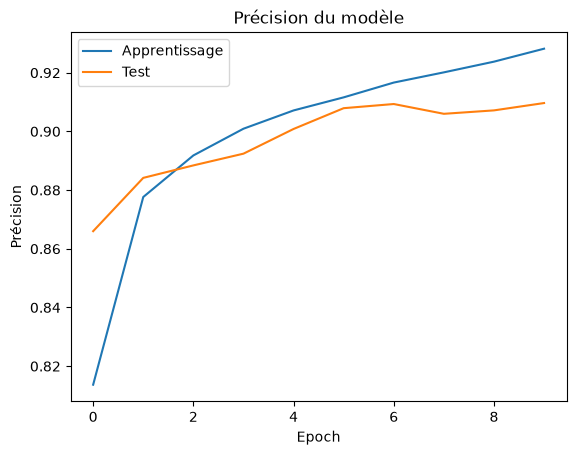

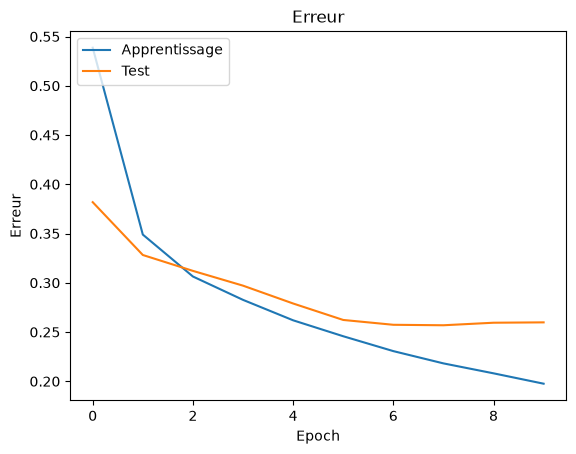

In [31]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
### Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

### Augmentation du nombre de données

In [32]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(rotation_range=8, width_shift_range=0.08, shear_range=0.3, height_shift_range=0.08, zoom_range=0.08)

In [33]:
nouvelles_images_apprentissage = generateur_images.flow(X_apprentissage, y_apprentissage, batch_size=256)

nouvelles_images_validation = generateur_images.flow(X_validation, y_validation, batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch=48000//256, epochs=50, validation_data=nouvelles_images_validation,validation_steps=12000//256,verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 37s 190ms/step - accuracy: 0.8273 - loss: 0.4609 - val_accuracy: 0.8454 - val_loss: 0.4077
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8477 - loss: 0.4320 - val_accuracy: 0.8452 - val_loss: 0.4144
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 37s 197ms/step - accuracy: 0.8513 - loss: 0.4027 - val_accuracy: 0.8592 - val_loss: 0.3860
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8789 - loss: 0.3602 - val_accuracy: 0.8587 - val_loss: 0.3849
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 89s 476ms/step - accuracy: 0.8553 - loss: 0.3835 - val_accuracy: 0.8494 - val_loss: 0.3972
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.8555 - loss: 0.4577 - val_accuracy: 0.8604 - val_loss: 0.3828
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 76s 405ms/step - accuracy: 0.8645 - loss: 0.3688 - val_accuracy: 0.8669 - val_loss: 0.3613
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 58ms/step - accuracy: 0.8672 - loss: 0.3350 -

### Sauvegarde du modèle

In [34]:
import os

os.makedirs("modele", exist_ok=True)

model_json = reseauNeurone1Convolution.to_json()
with open("modele/modele.json", "w") as json_file:json_file.write(model_json)

reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


In [35]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

In [36]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(X_apprentissage, y_apprentissage, batch_size=256,epochs=10, verbose=1, validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 402s 2s/step - accuracy: 0.7271 - loss: 0.7915 - val_accuracy: 0.2717 - val_loss: 2.3509
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 381s 2s/step - accuracy: 0.8383 - loss: 0.4500 - val_accuracy: 0.5848 - val_loss: 1.3265
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 271s 1s/step - accuracy: 0.8687 - loss: 0.3706 - val_accuracy: 0.8361 - val_loss: 0.4459
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 156s 831ms/step - accuracy: 0.8812 - loss: 0.3315 - val_accuracy: 0.8963 - val_loss: 0.2875
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 438s 2s/step - accuracy: 0.8900 - loss: 0.3091 - val_accuracy: 0.9029 - val_loss: 0.2586
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 618s 3s/step - accuracy: 0.8976 - loss: 0.2846 - val_accuracy: 0.9035 - val_loss: 0.2746
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 569s 3s/step - accuracy: 0.9030 - loss: 0.2711 - val_accuracy: 0.9135 - val_loss: 0.2422
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 409s 2s/step - accuracy: 0.9072 - loss: 0.2595 - val_a

In [37]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur :', evaluation[0])
print('Précision :', evaluation[1])

Erreur : 0.21888896822929382
Précision : 0.9211000204086304


In [38]:
historique_apprentissage = reseauNeurones4Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch=48000//256, epochs=50, validation_data=nouvelles_images_validation, validation_steps=12000//256, verbose=1)

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision :', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 461s 2s/step - accuracy: 0.8536 - loss: 0.4044 - val_accuracy: 0.8511 - val_loss: 0.4094
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 38s 195ms/step - accuracy: 0.8789 - loss: 0.3102 - val_accuracy: 0.8499 - val_loss: 0.3992
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 329s 2s/step - accuracy: 0.8687 - loss: 0.3615 - val_accuracy: 0.8867 - val_loss: 0.3071
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 40s 205ms/step - accuracy: 0.8281 - loss: 0.4073 - val_accuracy: 0.8815 - val_loss: 0.3199
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.8743 - loss: 0.3475 - val_accuracy: 0.8728 - val_loss: 0.3553
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 42s 222ms/step - accuracy: 0.8438 - loss: 0.4147 - val_accuracy: 0.8726 - val_loss: 0.3549
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 336s 2s/step - accuracy: 0.8810 - loss: 0.3332 - val_accuracy: 0.8934 - val_loss: 0.2843
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 39s 199ms/step - accuracy: 0.8477 - loss: 0.3484 - 